# 08b — Post-hoc improvements (labelled post-hoc)

Notebook 08 scored the pre-registered models once; this notebook asks
whether the failures it found can be repaired, **after** the test cohort has
been seen. To keep that honest, the first cell writes the protocol to
`docs/decisions.md` (#34) before anything is fitted: a fixed list of five
candidates, chosen on the 2016 cohort only, and one scoring of the chosen
candidate on the 2017–2019 test cohort. The registered verdicts of notebook
08 do not change; every result here is post-hoc.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet` | notebooks 02/04 — refits |
| in | `results/dt_tuning.json`, `results/cox_penalizer_tuning.csv` | notebooks 05–06 — settings reused unchanged |
| in | `data/processed/predictions_trackA.parquet`, `results/dt_validation_2016.csv`, `results/cox_validation_calibration.csv` | notebooks 05–06 — stored predictions (checks) and Cox test predictions |
| in | `results/success_criteria_registered.json`, `results/metrics.csv` | notebook 08 — registered rules, seeds and the registered scores |
| out | `docs/decisions.md` (#34), `results/posthoc_protocol.json` | the protocol, written before any fit |
| out | `results/posthoc_validation_2016.csv`, `results/posthoc_choice.json`, `results/posthoc_parameters.csv` | the choice on 2016 and the fitted weights / recalibration |
| out | `results/posthoc_metrics.csv`, `results/posthoc_criteria.csv`, `results/posthoc_all_candidates_test.csv`, `results/posthoc_size_subset.csv`, `results/posthoc_checks.csv` | test scores of the chosen candidate (post-hoc), all candidates (not used for the choice), checks |
| out | `figures/08b_posthoc_improvements/*.png|svg`, `report/figure_notes.md` | figures |

## 0. The protocol, written before anything is fitted

In [1]:
# Protocol: this cell reads no data
import json
import re
from pathlib import Path

REPO = Path.cwd().resolve().parent

DECISION_34 = """34. **Post-hoc improvement analysis, notebook 08b** (Alan, 2026-10-05, after
    notebook 08 had been scored; written by the first cell of notebook 08b
    and committed on its own before any candidate was fitted). The
    registered verdicts of decision #5 stand; everything in notebook 08b is
    labelled post-hoc.
    *Aim:* the failures found in notebooks 08–09 — calibration slope 1.34
    and 1.27 at 3 and 5 years, PJM over-prediction with the congestion
    artefact of figure 09_09, and the 7-year horizon, where Cox ranks best.
    *Candidates (fixed list):* K0 the main discrete-time LightGBM
    (reference); K1 LightGBM fitted with congestion held at its entry value
    in every project-year, as at prediction; K2 a blend of the main
    discrete-time logit, Cox and LightGBM, weights ≥ 0 summing to 1 on a 0.1
    grid, chosen per horizon; K3 the main LightGBM after a logistic
    recalibration (intercept and slope on the logit scale) per horizon; K4 a
    blend as in K2 of the entry-congestion logit and LightGBM with Cox.
    Model settings are notebook 06's and notebook 05's; nothing else is
    tuned.
    *Choice, on the 2016 cohort only:* every component is fitted on entrants
    to 2015 and predicts the 2016 entrants (all followed for at least eight
    years, so no censoring weights are needed); blend weights and
    recalibrations are fitted on those 2016 predictions and their 2016 score
    is cross-fitted on two halves (seed 34). The candidate with the lowest
    mean Brier score over 3, 5 and 7 years is chosen; K0 stays unless another
    candidate is lower.
    *Final model:* the chosen candidate's components refitted on entrants
    to 2016, with weights or recalibration fitted on all 2016 predictions of
    the fits to 2015; scored once on the 2017–2019 test cohort with notebook
    08's metrics, seed and criteria rules (`results/posthoc_criteria.csv`).
    All five candidates are also scored on the test cohort, in a table
    marked "not used for the choice".
    *Not attempted:* a trend term for the slowdown of 2018–2019 entrants —
    it happened after the 2016 validation year, so no choice about it can be
    made without the test years.
    *Rejected:* choosing among candidates on the test cohort; any change
    after the post-hoc test scores are seen.
"""

PROTOCOL = {
    "decided": "2026-10-05",
    "candidates": {"K0": "main discrete-time LightGBM (reference)",
                   "K1": "LightGBM fitted with congestion held at its entry value",
                   "K2": "blend of main logit, Cox and LightGBM (weights on a 0.1 simplex grid, per horizon)",
                   "K3": "main LightGBM with logistic recalibration per horizon",
                   "K4": "blend of entry-congestion logit and LightGBM with Cox"},
    "selection_cohort": 2016, "selection_metric": "mean IPCW Brier over 3, 5, 7 years",
    "cross_fit_folds": 2, "cross_fit_seed": 34, "blend_step": 0.1,
    "selection_bootstrap_seed": 340, "test_bootstrap_seed": 800, "n_boot": 200,
}

decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8").rstrip("\n") + "\n"
entry = re.compile(r"^34\. \*\*Post-hoc improvement analysis.*?(?=^35\. \*\*|\Z)", re.M | re.S)
updated = entry.sub(lambda _: DECISION_34, text) if entry.search(text) else text + DECISION_34
if updated != text:
    decisions_file.write_text(updated, encoding="utf-8")
(REPO / "results" / "posthoc_protocol.json").write_text(json.dumps(PROTOCOL, indent=2), encoding="utf-8")
print(f"decision #34 {'written' if updated != text else 'already in place'}; candidates: {list(PROTOCOL['candidates'])}")

decision #34 already in place; candidates: ['K0', 'K1', 'K2', 'K3', 'K4']


## Setup

Refits use `discrete_time.fit_both` / `predict_both` (with
`congestion="entry"` for K1 and K4) and
`survival_tools.fit_cause_specific_cox`; blends and recalibrations are in
`src/posthoc.py` (`fit_blend`, `fit_recalibration`, `apply_recalibration`,
`cross_fit`); scoring is notebook 08's `src/evaluation.py`.

In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, evaluation, explain, paths, plots, posthoc, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "08b_posthoc_improvements"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/08b_posthoc_improvements/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
REGISTERED = json.loads((paths.RESULTS / "success_criteria_registered.json").read_text(encoding="utf-8"))
N_BOOT = PROTOCOL["n_boot"]
CANDIDATES = list(PROTOCOL["candidates"])
CAND_LABELS = {"K0": "K0 LightGBM (main)", "K1": "K1 LightGBM, entry congestion", "K2": "K2 blend logit/Cox/LightGBM",
               "K3": "K3 LightGBM recalibrated", "K4": "K4 blend, entry congestion"}
CAND_STYLE = {"K0": dict(color="#CC79A7", marker="^"), "K1": dict(color="#D55E00", marker="v"),
              "K2": dict(color="#0072B2", marker="o"), "K3": dict(color="#E69F00", marker="s"),
              "K4": dict(color="#009E73", marker="D")}
BASE_STYLE = dict(color="#999999", marker="s", linestyle="--")
OFFSETS = dict(zip(["baseline"] + CANDIDATES, np.linspace(-0.25, 0.25, 6)))


def value(table, model, metric, horizon, column="estimate"):
    """One number from a summarised metrics table."""
    part = table[(table["model"] == model) & (table["metric"] == metric) & (table["horizon"] == horizon)]
    assert len(part) == 1, (model, metric, horizon)
    return part[column].iloc[0]


def follow_up(frame):
    """Years from each request to the censor date (its follow-up window)."""
    return ((pd.Timestamp(config.CENSOR_DATE) - frame["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()


def score_table(preds, durations, events, G, seed, reference):
    """Every metric at every horizon with bootstrap intervals and paired differences from `reference`."""
    tables = []
    for h in HORIZONS:
        point = evaluation.score_horizon(preds[h], durations, events, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(preds[h], durations, events, h, G, sw),
                                     len(durations), N_BOOT, seed)
        table = evaluation.summarise(point, draws, reference=reference)
        table.insert(2, "horizon", h)
        tables.append(table)
    return pd.concat(tables, ignore_index=True)

## 1. Components fitted on entrants to 2015, predicting the 2016 cohort

The discrete-time logit and LightGBM are refitted twice on entrants to 2015 —
with yearly congestion (the main version) and with congestion held at its
entry value — and Cox once, with notebook 05's penalties. The main versions
must reproduce notebooks 05 and 06's 2016 numbers, or the comparison would
not be with the models that were scored.

In [3]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tune = track_a[track_a["q_year"] <= config.TUNE_MAX_YEAR]
valid = track_a[track_a["q_year"] == config.VALIDATION_YEAR]
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)]
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
pen_table = pd.read_csv(paths.RESULTS / "cox_penalizer_tuning.csv")
PENALTY = pen_table.loc[pen_table.groupby("cause")["validation_log_likelihood"].idxmax()].set_index("cause")["penalizer"].to_dict()
print("Cox penalties (notebook 05):", PENALTY)


def components(train, target):
    """P(operation by 3/5/7 yr) of the five component models fitted on `train`, for `target`."""
    out = {}
    for version in ["main", "entry"]:
        fitted = discrete_time.fit_both(train, clean, tuning, congestion="yearly" if version == "main" else "entry")
        pred = discrete_time.predict_both(fitted, target)
        out[f"logit_{version}"] = {h: pred["dt_logit"][h].to_numpy() for h in HORIZONS}
        out[f"lgbm_{version}"] = {h: pred["dt_lgbm"][h].to_numpy() for h in HORIZONS}
    cox = {cause: survival_tools.fit_cause_specific_cox(train, cause, PENALTY[cause]) for cause in ["operation", "withdrawal"]}
    cif = survival_tools.cause_specific_cif(cox["operation"], cox["withdrawal"], survival_tools.cox_design(target), HORIZONS)
    out["cox"] = {h: cif[h].to_numpy() for h in HORIZONS}
    return out


comp16 = components(tune, valid)
check06 = pd.read_csv(paths.RESULTS / "dt_validation_2016.csv")
check05 = pd.read_csv(paths.RESULTS / "cox_validation_calibration.csv")
gap06 = max(abs(comp16["lgbm_main"][r.horizon][valid["region"].to_numpy() == r.region].mean() - r.dt_lgbm) for r in check06.itertuples())
gap05 = max(abs(comp16["cox"][r.horizon][valid["region"].to_numpy() == r.region].mean() - r.cox) for r in check05.itertuples())
print(f"2016 region means vs notebooks 06 (LightGBM) and 05 (Cox): largest gaps {gap06:.1e} and {gap05:.1e}")
d16, e16 = valid["duration_years"].to_numpy(), valid["event"].to_numpy()
fu16 = follow_up(valid)
G16 = evaluation.censoring_km(fu16, np.ones(len(valid), dtype=bool))
print(f"2016 cohort: {len(valid)} requests; shortest follow-up {fu16.min():.2f} years; G16(7) = {float(G16(7)):.3f}")

Cox penalties (notebook 05): {'operation': 0.01, 'withdrawal': 1.0}


2016 region means vs notebooks 06 (LightGBM) and 05 (Cox): largest gaps 8.3e-17 and 9.7e-17
2016 cohort: 573 requests; shortest follow-up 8.01 years; G16(7) = 1.000


## 2. The five candidates on the 2016 cohort

K0 and K1 are scored as they are. K2, K3 and K4 have parameters fitted on the
2016 cohort itself (blend weights, recalibration), so their 2016 predictions
are cross-fitted: each half of the cohort is predicted with parameters fitted
on the other half. The registered rule picks the lowest mean Brier score over
the three horizons.

In [4]:
def blend_matrix(comp, version, h):
    """Columns logit, Cox, LightGBM for one horizon (main or entry-congestion versions)."""
    return np.column_stack([comp[f"logit_{version}"][h], comp["cox"][h], comp[f"lgbm_{version}"][h]])


n16 = len(valid)
cand16 = {h: {} for h in HORIZONS}
for h in HORIZONS:
    y, w = evaluation.horizon_outcome(d16, e16, h, G16)
    cand16[h]["K0"] = comp16["lgbm_main"][h]
    cand16[h]["K1"] = comp16["lgbm_entry"][h]
    for key, version in [("K2", "main"), ("K4", "entry")]:
        P = blend_matrix(comp16, version, h)
        cand16[h][key] = posthoc.cross_fit(lambda idx, P=P, y=y, w=w: posthoc.fit_blend(P[idx], y[idx], w[idx], PROTOCOL["blend_step"]),
                                           lambda g, idx, P=P: P[idx] @ g, n16, PROTOCOL["cross_fit_folds"], PROTOCOL["cross_fit_seed"])
    p0 = comp16["lgbm_main"][h]
    cand16[h]["K3"] = posthoc.cross_fit(lambda idx, y=y, w=w: posthoc.fit_recalibration(p0[idx], y[idx], w[idx]),
                                        lambda c, idx: posthoc.apply_recalibration(p0[idx], c), n16,
                                        PROTOCOL["cross_fit_folds"], PROTOCOL["cross_fit_seed"])
    cand16[h] = {k: cand16[h][k] for k in CANDIDATES}
val16 = score_table(cand16, d16, e16, G16, PROTOCOL["selection_bootstrap_seed"], reference="K0")
val16.to_csv(paths.RESULTS / "posthoc_validation_2016.csv", index=False)
mean_brier = val16[val16["metric"] == "brier"].groupby("model")["estimate"].mean().loc[CANDIDATES]
lower = mean_brier[mean_brier < mean_brier["K0"]]
CHOSEN = lower.idxmin() if len(lower) else "K0"
choice = {"chosen": CHOSEN, "label": CAND_LABELS[CHOSEN], "mean_brier_2016": mean_brier.round(6).to_dict(),
          "rule": PROTOCOL["selection_metric"] + "; K0 unless another candidate is lower"}
(paths.RESULTS / "posthoc_choice.json").write_text(json.dumps(choice, indent=2), encoding="utf-8")
CHOICE_TIME = time.time()
print(f"mean 2016 Brier (3/5/7 yr): {mean_brier.round(5).to_dict()}")
print(f"chosen by the registered rule: {CHOSEN} — {CAND_LABELS[CHOSEN]}")
show = val16[val16["metric"].isin(["brier", "uno_c", "slope"])].copy()
show["value"] = [f"{r.estimate:.4f} [{r.low:.4f}, {r.high:.4f}]" for r in show.itertuples()]
show.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[CANDIDATES]

mean 2016 Brier (3/5/7 yr): {'K0': 0.0996, 'K1': 0.09959, 'K2': 0.09975, 'K3': 0.09975, 'K4': 0.0994}
chosen by the registered rule: K4 — K4 blend, entry congestion


model                                K0                       K1                       K2                       K3                       K4
metric horizon                                                                                                                             
brier  3        0.0553 [0.0429, 0.0738]  0.0554 [0.0429, 0.0747]  0.0559 [0.0431, 0.0743]  0.0558 [0.0428, 0.0746]  0.0559 [0.0427, 0.0745]
       5        0.1067 [0.0908, 0.1257]  0.1071 [0.0893, 0.1255]  0.1067 [0.0901, 0.1248]  0.1067 [0.0912, 0.1242]  0.1067 [0.0897, 0.1249]
       7        0.1368 [0.1159, 0.1588]  0.1363 [0.1154, 0.1573]  0.1367 [0.1158, 0.1583]  0.1367 [0.1162, 0.1577]  0.1357 [0.1156, 0.1566]
slope  3        0.9591 [0.7387, 1.1667]  0.9726 [0.7257, 1.2091]  1.1119 [0.8784, 1.3882]  0.9920 [0.7870, 1.2100]  1.1104 [0.8676, 1.3866]
       5        0.8789 [0.6656, 1.0859]  0.9260 [0.6880, 1.1504]  0.9654 [0.7339, 1.1971]  0.9922 [0.7478, 1.2466]  0.9892 [0.7269, 1.2349]
       7        0.9146 [0.6993, 1.1565]  1.0386 [0.7722, 1.3300]  0.9446 [0.7281, 1.1968]  0.9870 [0.7497, 1.2563]  1.0902 [0.8336, 1.3827]
uno_c  3        0.8166 [0.7605, 0.8616]  0.8034 [0.7459, 0.8489]  0.8210 [0.7679, 0.8631]  0.8165 [0.7622, 0.8619]  0.8121 [0.7532, 0.8552]
       5        0.7322 [0.6778, 0.7765]  0.7109 [0.6557, 0.7539]  0.7307 [0.6765, 0.7754]  0.7323 [0.6804, 0.7762]  0.7224 [0.6700, 0.7664]
       7        0.7091 [0.6693, 0.7565]  0.6874 [0.6401, 0.7387]  0.7113 [0.6700, 0.7597]  0.7068 [0.6655, 0.7541]  0.7062 [0.6657, 0.7535]

paired Brier intervals against K0 that include zero: 12 of 12


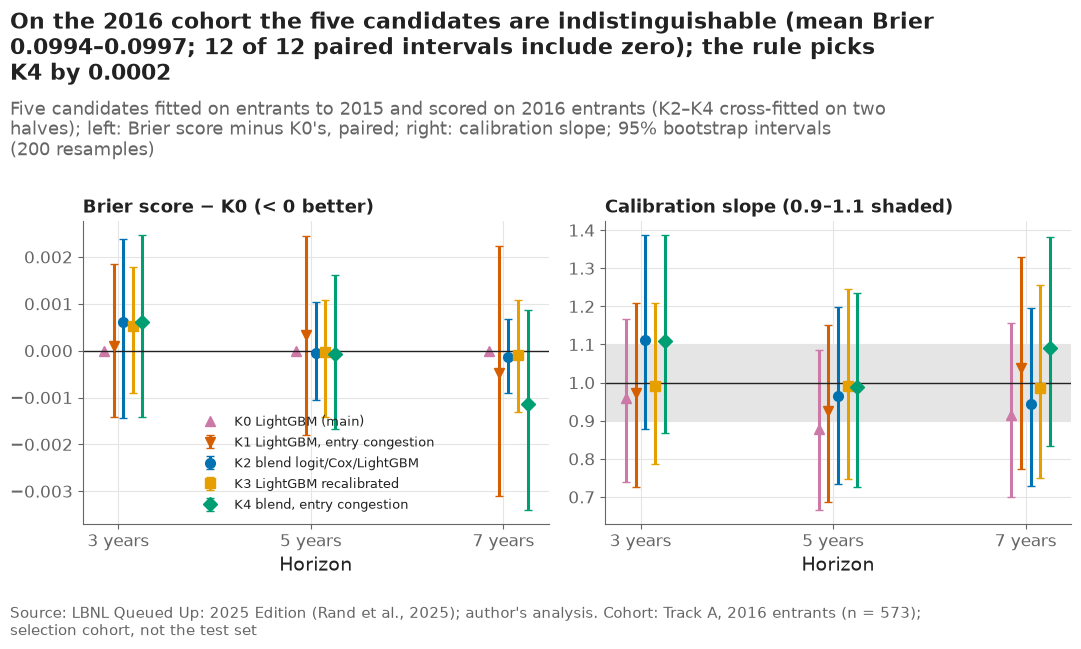

In [5]:
fig, axes = plt.subplots(1, 2, sharex=True)
for model in CANDIDATES:
    part = val16[(val16["model"] == model) & (val16["metric"] == "brier")]
    x = part["horizon"] + OFFSETS[model]
    if model == "K0":
        axes[0].plot(x, np.zeros(len(part)), linestyle="none", label=CAND_LABELS[model], **CAND_STYLE[model])
    else:
        axes[0].errorbar(x, part["diff"], yerr=[part["diff"] - part["diff_low"], part["diff_high"] - part["diff"]], capsize=3,
                         linestyle="none", label=CAND_LABELS[model], **CAND_STYLE[model])
    sl = val16[(val16["model"] == model) & (val16["metric"] == "slope")]
    axes[1].errorbar(sl["horizon"] + OFFSETS[model], sl["estimate"], yerr=[sl["estimate"] - sl["low"], sl["high"] - sl["estimate"]],
                     capsize=3, linestyle="none", **CAND_STYLE[model])
axes[0].axhline(0, color=plots.INK, linewidth=1)
axes[1].axhspan(0.9, 1.1, color="#E5E5E5")
axes[1].axhline(1, color=plots.INK, linewidth=1)
for ax in axes:
    ax.set_xticks(HORIZONS, [f"{h} years" for h in HORIZONS])
    ax.set_xlabel("Horizon")
axes[0].set_title("Brier score − K0 (< 0 better)", fontsize=13)
axes[1].set_title("Calibration slope (0.9–1.1 shaded)", fontsize=13)
axes[0].legend(loc="best", fontsize=9.5)
cmp = val16[(val16["metric"] == "brier") & val16["diff"].notna()]
n_span = int(((cmp["diff_low"] < 0) & (cmp["diff_high"] > 0)).sum())
print(f"paired Brier intervals against K0 that include zero: {n_span} of {len(cmp)}")
plots.finish(fig,
             f"On the 2016 cohort the five candidates are indistinguishable (mean Brier {mean_brier.min():.4f}–"
             f"{mean_brier.max():.4f}; {n_span} of {len(cmp)} paired intervals include zero); the rule picks {CHOSEN} by "
             f"{mean_brier['K0'] - mean_brier[CHOSEN]:.4f}",
             "Five candidates fitted on entrants to 2015 and scored on 2016 entrants (K2–K4 cross-fitted on two halves); "
             "left: Brier score minus K0's, paired; right: calibration slope; 95% bootstrap intervals (200 resamples)",
             f"Track A, 2016 entrants (n = {n16}); selection cohort, not the test set")
save(fig, "08b_01_choice_on_2016", "The five post-hoc candidates on the 2016 cohort: Brier score relative to the main LightGBM and calibration slope.")
plt.show()

**Reading this.** Fitted on entrants to 2015 and scored on the 573 entrants of 2016 (all followed for at least 8.01 years, so G16(7) = 1.000 and no weights are needed), the five candidates are practically tied: mean Brier scores over 3, 5 and 7 years of 0.0996 (K0), 0.09959 (K1), 0.09975 (K2, K3) and 0.0994 (K4). The registered rule picks K4, the blend with entry-time congestion, by 0.0002 — and all 12 paired intervals against K0 include zero, so the choice is a rule being applied, not evidence that K4 is better. The main components reproduce notebooks 05 and 06 exactly on this cohort (gaps 8.3e-17 and 9.7e-17), so the comparison is with the models notebook 08 scored. One result explains why no 2016-based repair could fix notebook 08's main calibration failure: on 2016 the main LightGBM was already calibrated (slopes 0.96, 0.88, 0.91), while on the test cohort its slopes were 1.34 and 1.27. The miscalibration appeared only in entry years the 2016 cohort cannot show.

## 3. The final components and parameters

Components are refitted on entrants to 2016; blend weights and
recalibrations are fitted on all 2016 predictions of the fits to 2015 and
applied to the final fits' test predictions. The main LightGBM refit must
equal the predictions notebook 08 scored.

In [6]:
compT = components(final, test)
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
keys = test["project_key"].astype(str)
stored = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[keys] for h in HORIZONS}
gap_main = max(max(float(np.abs(compT["lgbm_main"][h] - stored[h]["dt_lgbm"].to_numpy()).max()),
                   float(np.abs(compT["logit_main"][h] - stored[h]["dt_logit"].to_numpy()).max()),
                   float(np.abs(compT["cox"][h] - stored[h]["cox"].to_numpy()).max())) for h in HORIZONS)
print(f"largest gap between the refitted main components and the predictions notebook 08 scored: {gap_main:.1e}")
param_rows, candT = [], {h: {} for h in HORIZONS}
for h in HORIZONS:
    y, w = evaluation.horizon_outcome(d16, e16, h, G16)
    candT[h]["K0"] = compT["lgbm_main"][h]
    candT[h]["K1"] = compT["lgbm_entry"][h]
    for key, version in [("K2", "main"), ("K4", "entry")]:
        g = posthoc.fit_blend(blend_matrix(comp16, version, h), y, w, PROTOCOL["blend_step"])
        candT[h][key] = blend_matrix(compT, version, h) @ g
        param_rows.append({"candidate": key, "horizon": h, "w_logit": g[0], "w_cox": g[1], "w_lgbm": g[2]})
    coef = posthoc.fit_recalibration(comp16["lgbm_main"][h], y, w)
    candT[h]["K3"] = posthoc.apply_recalibration(compT["lgbm_main"][h], coef)
    param_rows.append({"candidate": "K3", "horizon": h, "intercept": coef[0], "slope": coef[1]})
    candT[h] = {k: candT[h][k] for k in CANDIDATES}
parameters = pd.DataFrame(param_rows)
parameters.to_csv(paths.RESULTS / "posthoc_parameters.csv", index=False)
parameters.round(3)

largest gap between the refitted main components and the predictions notebook 08 scored: 6.9e-18


,candidate,horizon,w_logit,w_cox,w_lgbm,intercept,slope
0,K2,3,0.0,0.2,0.8,NaN,NaN
1,K4,3,0.2,0.1,0.7,NaN,NaN
2,K3,3,NaN,NaN,NaN,-0.152,0.959
3,K2,5,0.0,0.2,0.8,NaN,NaN
4,K4,5,0.3,0.0,0.7,NaN,NaN
5,K3,5,NaN,NaN,NaN,-0.095,0.879
6,K2,7,0.3,0.0,0.7,NaN,NaN
7,K4,7,0.3,0.0,0.7,NaN,NaN
8,K3,7,NaN,NaN,NaN,-0.027,0.915


**Reading this.** The refitted main components equal the predictions notebook 08 scored (largest gap 6.9e-18). Fitted on all 2016 predictions, the blends lean on LightGBM: K2 gives it 0.8 at 3 and 5 years and 0.7 at 7 years (Cox 0.2, 0.2, 0; logit 0, 0, 0.3); K4 gives it 0.7 at every horizon, with the logit at 0.2–0.3 and Cox at 0.1 or 0. The recalibration of K3 has slopes 0.959, 0.879 and 0.915 — on 2016 it pulls LightGBM's predictions towards the mean — which is the opposite of what the test cohort needed.

## 4. The chosen candidate on the test cohort (post-hoc)

Scored once, with notebook 08's metrics, censoring weights and bootstrap
seed, next to the baseline and the registered primary model; the criteria
C1–C4 are applied with their registered rules. C5 concerns Track B, which
this notebook does not change.

In [7]:
durT, evT = test["duration_years"].to_numpy(), test["event"].to_numpy()
GT = evaluation.censoring_km(follow_up(test), np.ones(len(test), dtype=bool))
first_test_score = time.time()
predsT = {h: {"baseline": stored[h]["baseline"].to_numpy(), "dt_lgbm": compT["lgbm_main"][h], "posthoc": candT[h][CHOSEN]}
          for h in HORIZONS}
post = score_table(predsT, durT, evT, GT, PROTOCOL["test_bootstrap_seed"], reference="baseline")
post.insert(0, "chosen", CHOSEN)
post.to_csv(paths.RESULTS / "posthoc_metrics.csv", index=False)
crit_rows = []
for c in [c for c in REGISTERED["criteria"] if c["track"] == "A"]:
    for h in c["horizons"]:
        for model in ["dt_lgbm", "posthoc"]:
            row = post[(post["model"] == model) & (post["metric"] == c["metric"]) & (post["horizon"] == h)].iloc[0]
            if c["rule"] == "beat":
                passed = bool(row["beats"])
            elif c["rule"] == "between":
                passed = c["low"] <= row["estimate"] <= c["high"]
            else:
                passed = row["estimate"] >= c["value"]
            crit_rows.append({"id": c["id"], "metric": c["metric"], "horizon": h, "model": model,
                              "estimate": row["estimate"], "low": row["low"], "high": row["high"],
                              "diff": row.get("diff"), "diff_low": row.get("diff_low"), "diff_high": row.get("diff_high"),
                              "result": "PASS" if passed else "FAIL"})
post_criteria = pd.DataFrame(crit_rows)
post_criteria["status"] = np.where(post_criteria["model"] == "posthoc", "post-hoc", "registered (notebook 08)")
post_criteria.to_csv(paths.RESULTS / "posthoc_criteria.csv", index=False)
registered_rows = pd.read_csv(paths.RESULTS / "success_criteria.csv")
same = post_criteria[post_criteria["model"] == "dt_lgbm"].reset_index(drop=True)["result"].tolist() == \
    registered_rows[registered_rows["track"] == "A"]["result"].tolist()
n_post = int((post_criteria.loc[post_criteria["model"] == "posthoc", "result"] == "PASS").sum())
n_reg = int((post_criteria.loc[post_criteria["model"] == "dt_lgbm", "result"] == "PASS").sum())
print(f"chosen candidate {CHOSEN}: {n_post} of 10 Track A criterion lines pass post-hoc; registered LightGBM: {n_reg} of 10 "
      f"(same verdicts as notebook 08: {same})")
post_criteria.pivot_table(index=["id", "metric", "horizon"], columns="model", values=["estimate", "result"], aggfunc="first")

chosen candidate K4: 5 of 10 Track A criterion lines pass post-hoc; registered LightGBM: 6 of 10 (same verdicts as notebook 08: True)


estimate            result        
model                dt_lgbm   posthoc dt_lgbm posthoc
id metric  horizon                                    
C1 uno_c   3        0.852505  0.857250    PASS    PASS
           5        0.759738  0.738458    PASS    FAIL
           7        0.672238  0.656745    FAIL    FAIL
C2 brier   3        0.041145  0.041024    PASS    PASS
           5        0.080803  0.080293    PASS    PASS
           7        0.121071  0.120711    FAIL    FAIL
C3 slope   3        1.344823  1.396693    FAIL    FAIL
           5        1.272778  1.195859    FAIL    FAIL
           7        0.939463  0.927942    PASS    PASS
C4 lift_10 5        3.964758  3.964758    PASS    PASS

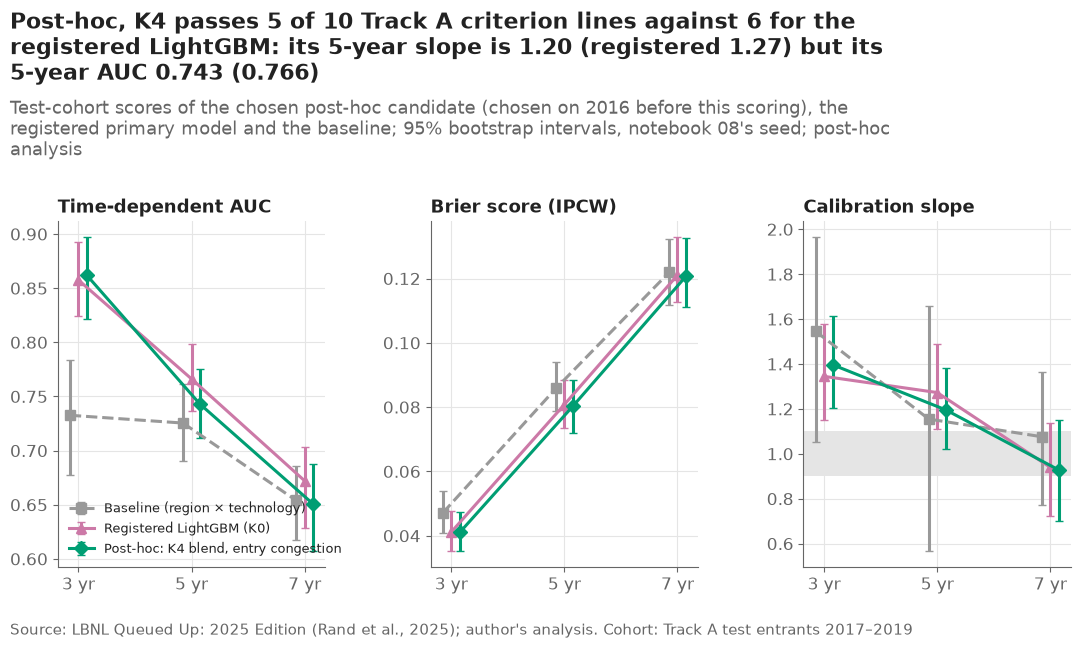

In [8]:
fig, axes = plt.subplots(1, 3, sharex=True)
styles = {"baseline": dict(BASE_STYLE, label="Baseline (region × technology)"),
          "dt_lgbm": dict(CAND_STYLE["K0"], label="Registered LightGBM (K0)"),
          "posthoc": dict(CAND_STYLE[CHOSEN], label=f"Post-hoc: {CAND_LABELS[CHOSEN]}")}
offs = {"baseline": -0.15, "dt_lgbm": 0, "posthoc": 0.15}
for ax, metric in zip(axes, ["auc", "brier", "slope"]):
    for model, style in styles.items():
        part = post[(post["model"] == model) & (post["metric"] == metric)]
        ax.errorbar(part["horizon"] + offs[model], part["estimate"],
                    yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], capsize=3, **style)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_title({"auc": "Time-dependent AUC", "brier": "Brier score (IPCW)", "slope": "Calibration slope"}[metric], fontsize=13)
axes[2].axhspan(0.9, 1.1, color="#E5E5E5")
axes[0].legend(loc="lower left", fontsize=9)
slopes = {m: [value(post, m, "slope", h) for h in HORIZONS] for m in ["dt_lgbm", "posthoc"]}
plots.finish(fig,
             f"Post-hoc, {CHOSEN} passes {n_post} of 10 Track A criterion lines against {n_reg} for the registered "
             f"LightGBM: its 5-year slope is {slopes['posthoc'][1]:.2f} (registered {slopes['dt_lgbm'][1]:.2f}) but its "
             f"5-year AUC {value(post, 'posthoc', 'auc', 5):.3f} ({value(post, 'dt_lgbm', 'auc', 5):.3f})",
             "Test-cohort scores of the chosen post-hoc candidate (chosen on 2016 before this scoring), the registered "
             "primary model and the baseline; 95% bootstrap intervals, notebook 08's seed; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_02_chosen_on_test", "Post-hoc: test-cohort AUC, Brier score and calibration slope of the chosen candidate, the registered LightGBM and the baseline.")
plt.show()

**Reading this.** Scored once on the test cohort, K4 passes 5 of the 10 Track A criterion lines, against 6 for the registered LightGBM; the registered model's verdicts reproduce notebook 08 exactly. K4 keeps C1 and C2 at 3 years (Uno 0.857, Brier 0.0410) and C2 at 5 years (0.0803), but loses C1 at 5 years (Uno 0.738, interval against the baseline no longer above zero), and still fails C1 and C2 at 7 years and C3 at 3 and 5 years (slopes 1.40 and 1.20); C3 at 7 years (0.93) and C4 (lift 3.96) pass as before. So the post-hoc repair does not improve the pre-registered picture: it trades a little ranking (5-year AUC 0.743 vs 0.766) for a slightly better 5-year slope. The registered result of notebook 08 stands as the project's main result.

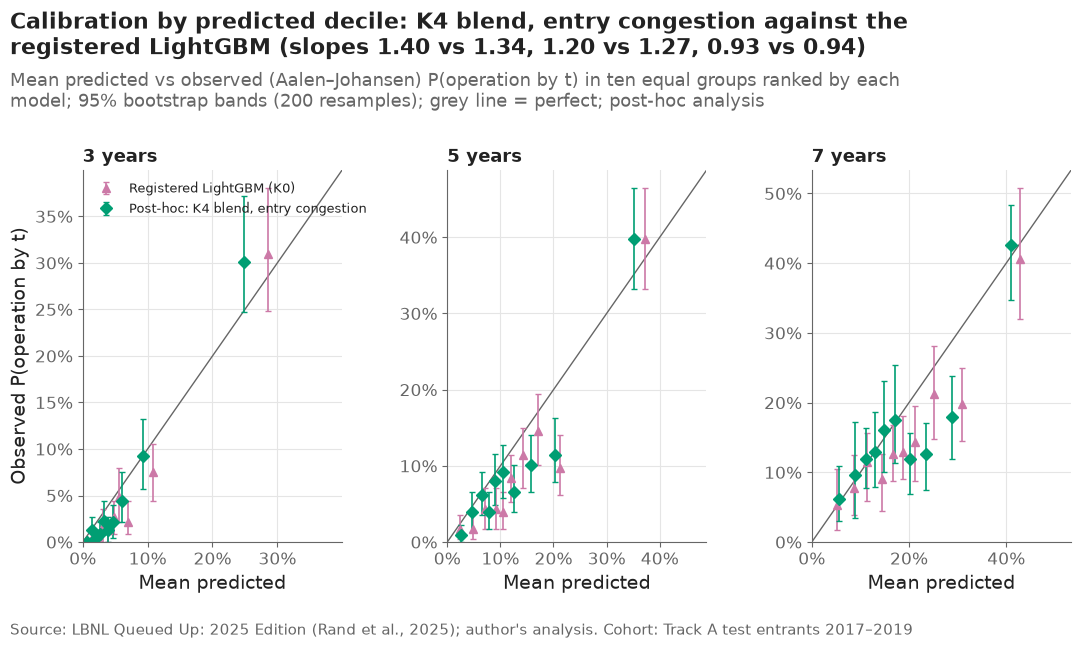

In [9]:
fig, axes = plt.subplots(1, 3)
cal_rows = []
for ax, h in zip(axes, HORIZONS):
    top = 0
    for model in ["dt_lgbm", "posthoc"]:
        p = predsT[h][model]
        groups = evaluation.decile_groups(p)
        for g in range(10):
            idx = groups == g
            obs = survival_tools.aalen_johansen(durT[idx], evT[idx], [h])["cif_operation"].iloc[0]
            band = survival_tools.bootstrap_bands(durT[idx], evT[idx], [h], n_boot=N_BOOT, seed=850 + g)
            cal_rows.append({"horizon": h, "model": model, "decile": g + 1, "predicted": p[idx].mean(), "observed": obs,
                             "low": band["cif_operation_low"].iloc[0], "high": band["cif_operation_high"].iloc[0]})
    part_h = pd.DataFrame([r for r in cal_rows if r["horizon"] == h])
    top = max(part_h["high"].max(), part_h["predicted"].max()) * 1.05
    ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
    for model in ["dt_lgbm", "posthoc"]:
        part = part_h[part_h["model"] == model]
        style = styles[model]
        ax.errorbar(part["predicted"], part["observed"], yerr=[part["observed"] - part["low"], part["high"] - part["observed"]],
                    fmt=style["marker"], color=style["color"], capsize=2, markersize=6, linewidth=1.2, label=style["label"])
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_title(f"{h} years", fontsize=13)
    ax.set_xlabel("Mean predicted")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Observed P(operation by t)")
axes[0].legend(loc="upper left", fontsize=9)
plots.finish(fig,
             f"Calibration by predicted decile: {CAND_LABELS[CHOSEN]} against the registered LightGBM (slopes "
             + ", ".join(f"{a:.2f} vs {b:.2f}" for a, b in zip(slopes["posthoc"], slopes["dt_lgbm"])) + ")",
             "Mean predicted vs observed (Aalen–Johansen) P(operation by t) in ten equal groups ranked by each model; 95% "
             "bootstrap bands (200 resamples); grey line = perfect; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_03_calibration_deciles", "Post-hoc: calibration by predicted decile of the chosen candidate and the registered LightGBM.")
plt.show()

**Reading this.** By predicted decile K4 sits a little closer to the diagonal at 5 years (slope 1.20 vs 1.27) and a little further at 3 years (1.40 vs 1.34); at 7 years both are near 1 (0.93 vs 0.94). Neither model's middle deciles reach the line at 3 and 5 years: the test requests in those groups completed less often than either model predicted.

cells (region or entry year × horizon) inside the observed band: {'baseline': 7, 'dt_lgbm': 7, 'posthoc': 12} of 18


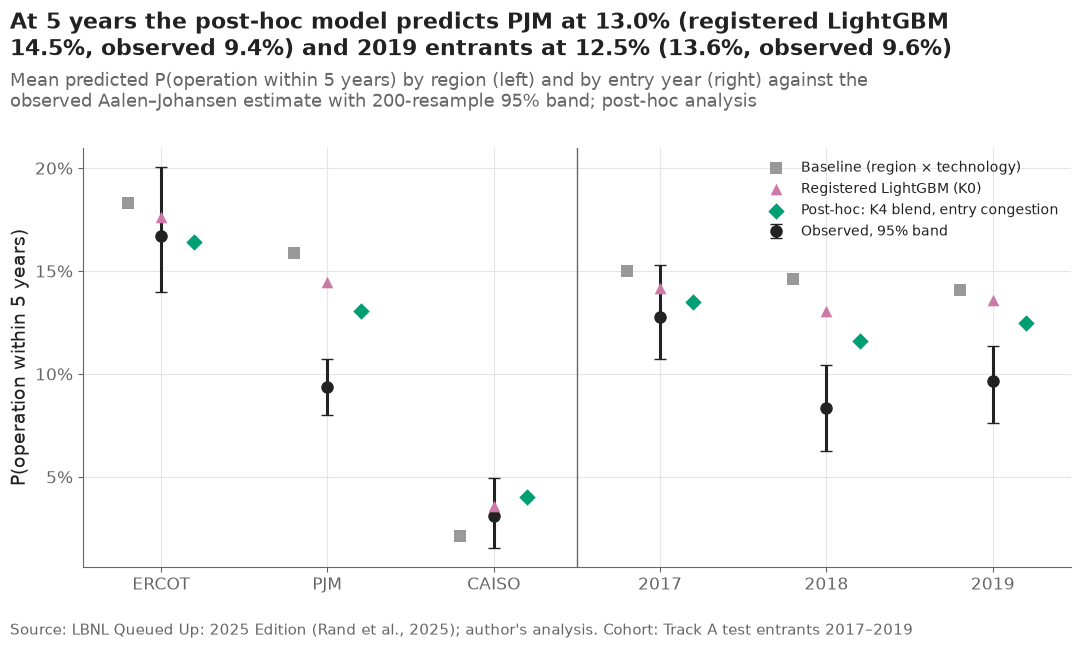

,group,horizon,observed,low,high,baseline,dt_lgbm,posthoc
0,ERCOT,3,0.054,0.038,0.075,0.090,0.080,0.071
1,ERCOT,5,0.167,0.140,0.200,0.183,0.176,0.164
2,ERCOT,7,0.215,0.179,0.258,0.230,0.250,0.234
3,PJM,3,0.059,0.047,0.071,0.100,0.077,0.065
4,PJM,5,0.094,0.080,0.107,0.159,0.145,0.130
5,PJM,7,0.167,0.143,0.194,0.203,0.204,0.189
6,CAISO,3,0.015,0.003,0.031,0.008,0.012,0.012
7,CAISO,5,0.031,0.015,0.049,0.021,0.036,0.040
8,CAISO,7,0.046,0.023,0.070,0.053,0.073,0.086
9,2017,3,0.053,0.035,0.071,0.087,0.073,0.063


In [10]:
regions = test["region"].astype(str).to_numpy()
reg_rows = []
for i, region in enumerate(config.TRACK_A_REGIONS):
    m = regions == region
    obs = survival_tools.aalen_johansen(durT[m], evT[m], HORIZONS)
    band = survival_tools.bootstrap_bands(durT[m], evT[m], HORIZONS, n_boot=N_BOOT, seed=820 + i)
    for j, h in enumerate(HORIZONS):
        reg_rows.append({"group": region, "horizon": h, "observed": obs["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         **{model: predsT[h][model][m].mean() for model in ["baseline", "dt_lgbm", "posthoc"]}})
for y_i, year in enumerate([2017, 2018, 2019]):
    m = test["q_year"].to_numpy() == year
    obs = survival_tools.aalen_johansen(durT[m], evT[m], HORIZONS)
    band = survival_tools.bootstrap_bands(durT[m], evT[m], HORIZONS, n_boot=N_BOOT, seed=830 + y_i)
    for j, h in enumerate(HORIZONS):
        reg_rows.append({"group": str(year), "horizon": h, "observed": obs["cif_operation"].iloc[j],
                         "low": band["cif_operation_low"].iloc[j], "high": band["cif_operation_high"].iloc[j],
                         **{model: predsT[h][model][m].mean() for model in ["baseline", "dt_lgbm", "posthoc"]}})
levels = pd.DataFrame(reg_rows)
lv5 = levels[levels["horizon"] == 5].set_index("group")
fig, ax = plt.subplots()
groups = list(lv5.index)
x = np.arange(len(groups))
ax.errorbar(x, lv5["observed"], yerr=[lv5["observed"] - lv5["low"], lv5["high"] - lv5["observed"]], fmt="o", color=plots.INK,
            capsize=4, markersize=8, label="Observed, 95% band")
for model, dx in [("baseline", -0.2), ("dt_lgbm", 0), ("posthoc", 0.2)]:
    ax.scatter(x + dx, lv5[model], marker=styles[model]["marker"], color=styles[model]["color"], s=70, zorder=3,
               label=styles[model]["label"])
ax.axvline(2.5, color=plots.MUTED, linewidth=1)
ax.set_xticks(x, [f"{g}" for g in groups])
ax.set_ylabel("P(operation within 5 years)")
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="upper right", fontsize=10)
inside = {m: int(((levels[m] >= levels["low"]) & (levels[m] <= levels["high"])).sum()) for m in ["baseline", "dt_lgbm", "posthoc"]}
print("cells (region or entry year × horizon) inside the observed band:", inside, "of", len(levels))
plots.finish(fig,
             f"At 5 years the post-hoc model predicts PJM at {lv5.loc['PJM', 'posthoc']:.1%} (registered LightGBM "
             f"{lv5.loc['PJM', 'dt_lgbm']:.1%}, observed {lv5.loc['PJM', 'observed']:.1%}) and 2019 entrants at "
             f"{lv5.loc['2019', 'posthoc']:.1%} ({lv5.loc['2019', 'dt_lgbm']:.1%}, observed {lv5.loc['2019', 'observed']:.1%})",
             "Mean predicted P(operation within 5 years) by region (left) and by entry year (right) against the observed "
             "Aalen–Johansen estimate with 200-resample 95% band; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_04_levels_by_group", "Post-hoc: mean predicted versus observed 5-year completion by region and entry year.")
plt.show()
levels.round(3)

**Reading this.** Where K4 does help is the average level. Its regional and entry-year averages are inside the observed 95% band in 12 of 18 cells, against 7 for the registered LightGBM and 7 for the baseline. At 5 years it predicts ERCOT at 16.4% (observed 16.7%), PJM at 13.0% (registered 14.5%, observed 9.4%, band 8.0–10.7%), and 2018 and 2019 entrants at 11.6% and 12.5% (registered 13.1% and 13.6%; observed 8.3% and 9.6%). PJM and the 2018–2019 entrants are still over-predicted — the slowdown after 2017 remains unrepaired, as the protocol expected — and CAISO at 7 years gets worse (8.6% vs 7.3%, observed 4.6%).

### Requests of 20 MW and more

Notebook 08 found that the registered model's advantage disappears when
requests under 20 MW are left out. The same question for the chosen
candidate, by scoring the test requests of 20 MW and more (no refit).

In [11]:
big = ~test["size_regime"].astype(str).isin(["<5", "5–<20"]).to_numpy()
G_big = evaluation.censoring_km(follow_up(test)[big], np.ones(big.sum(), dtype=bool))
big_preds = {h: {k: v[big] for k, v in predsT[h].items()} for h in HORIZONS}
big_table = score_table(big_preds, durT[big], evT[big], G_big, PROTOCOL["test_bootstrap_seed"], reference="baseline")
big_table.to_csv(paths.RESULTS / "posthoc_size_subset.csv", index=False)
print(f"test requests of 20 MW or more: {big.sum():,}")
bt = big_table[big_table["metric"].isin(["uno_c", "brier"]) & big_table["diff"].notna()].copy()
bt["vs baseline"] = [f"{r.diff:+.4f} [{r.diff_low:+.4f}, {r.diff_high:+.4f}]" for r in bt.itertuples()]
bt.pivot_table(index=["metric", "horizon"], columns="model", values="vs baseline", aggfunc="first")

test requests of 20 MW or more: 1,839


model                              dt_lgbm                     posthoc
metric horizon                                                        
brier  3        -0.0031 [-0.0045, -0.0018]  -0.0037 [-0.0050, -0.0024]
       5        -0.0037 [-0.0059, -0.0014]  -0.0043 [-0.0066, -0.0016]
       7        +0.0004 [-0.0032, +0.0035]  +0.0001 [-0.0036, +0.0039]
uno_c  3        +0.0790 [+0.0112, +0.1607]  +0.0702 [-0.0085, +0.1542]
       5        -0.0205 [-0.0532, +0.0159]  -0.0624 [-0.1092, -0.0128]
       7        +0.0103 [-0.0268, +0.0548]  -0.0231 [-0.0725, +0.0149]

**Reading this.** On the 1,839 test requests of 20 MW or more (scored without refitting), both models still have a slightly lower Brier score than the baseline at 3 and 5 years (registered −0.0031 [−0.0045, −0.0018] and −0.0037 [−0.0059, −0.0014]; K4 −0.0037 and −0.0043), but ranking adds little: the registered model's concordance gain is +0.079 [+0.011, +0.161] at 3 years and nil at 5 and 7 years, and K4 ranks these requests worse than the baseline at 5 years (−0.062 [−0.109, −0.013]). Together with notebook 08's refit without small requests (0 of 6 comparisons won), the conclusion holds: for utility-scale requests the models add little beyond region and technology.

## 5. All five candidates on the test cohort — not used for the choice

For transparency every candidate is scored on the test cohort. The choice
was fixed by section 2 (and written to `results/posthoc_choice.json`) before
this cell runs; a candidate that happens to score better here was not
chosen and must not be read as the answer.

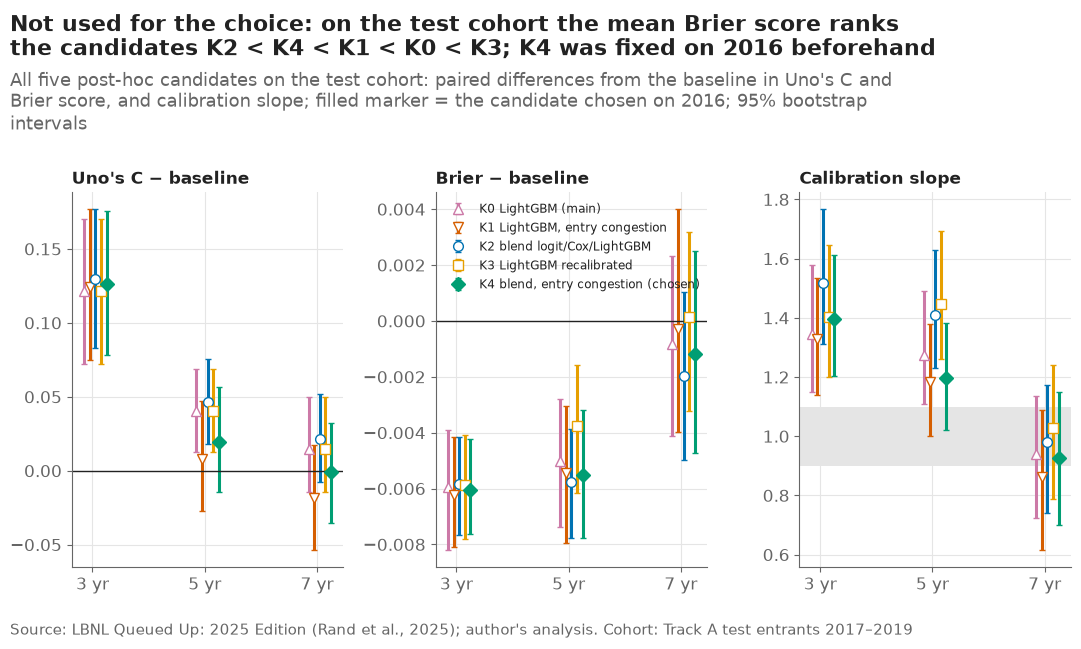

model          baseline      K0      K1      K2      K3      K4
metric horizon                                                 
brier  3         0.0471  0.0411  0.0409  0.0412  0.0412  0.0410
       5         0.0858  0.0808  0.0804  0.0800  0.0820  0.0803
       7         0.1219  0.1211  0.1216  0.1199  0.1220  0.1207
slope  3         1.5456  1.3448  1.3301  1.5177  1.4021  1.3967
       5         1.1547  1.2728  1.1832  1.4106  1.4481  1.1959
       7         1.0759  0.9395  0.8623  0.9816  1.0271  0.9279
uno_c  3         0.7311  0.8525  0.8552  0.8607  0.8525  0.8573
       5         0.7191  0.7597  0.7269  0.7653  0.7597  0.7385
       7         0.6574  0.6722  0.6390  0.6788  0.6722  0.6567

In [12]:
allT = {h: {"baseline": stored[h]["baseline"].to_numpy(), **candT[h]} for h in HORIZONS}
all_test = score_table(allT, durT, evT, GT, PROTOCOL["test_bootstrap_seed"], reference="baseline")
all_test.insert(0, "note", "not used for the choice")
all_test.to_csv(paths.RESULTS / "posthoc_all_candidates_test.csv", index=False)
fig, axes = plt.subplots(1, 3, sharex=True)
for ax, metric in zip(axes, ["uno_c", "brier", "slope"]):
    for model in CANDIDATES:
        part = all_test[(all_test["model"] == model) & (all_test["metric"] == metric)]
        if metric == "slope":
            est, low, high = part["estimate"], part["low"], part["high"]
        else:
            est, low, high = part["diff"], part["diff_low"], part["diff_high"]
        face = CAND_STYLE[model]["color"] if model == CHOSEN else "white"
        ax.errorbar(part["horizon"] + OFFSETS[model], est, yerr=[est - low, high - est], capsize=2, linestyle="none",
                    markerfacecolor=face, label=CAND_LABELS[model] + (" (chosen)" if model == CHOSEN else ""), **CAND_STYLE[model])
    if metric == "slope":
        ax.axhspan(0.9, 1.1, color="#E5E5E5")
    else:
        ax.axhline(0, color=plots.INK, linewidth=1)
    ax.set_xticks(HORIZONS, [f"{h} yr" for h in HORIZONS])
    ax.set_title({"uno_c": "Uno's C − baseline", "brier": "Brier − baseline", "slope": "Calibration slope"}[metric], fontsize=12)
axes[1].legend(loc="upper left", fontsize=8.5)
ranks = all_test[all_test["metric"] == "brier"].groupby("model")["estimate"].mean().loc[CANDIDATES]
plots.finish(fig,
             f"Not used for the choice: on the test cohort the mean Brier score ranks the candidates "
             + " < ".join(ranks.sort_values().index) + f"; {CHOSEN} was fixed on 2016 beforehand",
             "All five post-hoc candidates on the test cohort: paired differences from the baseline in Uno's C and Brier "
             "score, and calibration slope; filled marker = the candidate chosen on 2016; 95% bootstrap intervals",
             "Track A test entrants 2017–2019")
save(fig, "08b_05_all_candidates_test", "Post-hoc, not used for the choice: all five candidates on the test cohort.")
plt.show()
at = all_test[all_test["metric"].isin(["uno_c", "brier", "slope"])].copy()
at["value"] = [f"{r.estimate:.4f}" for r in at.itertuples()]
at.pivot_table(index=["metric", "horizon"], columns="model", values="value", aggfunc="first")[["baseline"] + CANDIDATES]

**Reading this.** Not used for the choice, and shown only so nothing is hidden: on the test cohort K2 (the blend of the main logit, Cox and LightGBM) has the best concordance at every horizon (0.861, 0.765, 0.679) and the lowest Brier scores at 5 and 7 years (0.0800, 0.1199), but the worst calibration slopes at 3 and 5 years (1.52, 1.41). Picking K2 now, because it scores best on the test cohort, would be exactly the selection on the test set that the protocol rules out, and its gains over K0 are inside the intervals. K3, the recalibrated LightGBM, made calibration worse (slopes 1.40, 1.45, 1.03), because the 2016 cohort asked for the opposite correction from the one the test cohort needed. The honest summary is that all five candidates perform within noise of one another.

## 6. Does fitting on entry-time congestion remove the artefact?

Notebook 09 traced the positive congestion effect to fitting on yearly
congestion. The same partial dependence as figure 09_05 for the LightGBM
fitted with congestion held at entry (K1's component), on entrants to 2016.

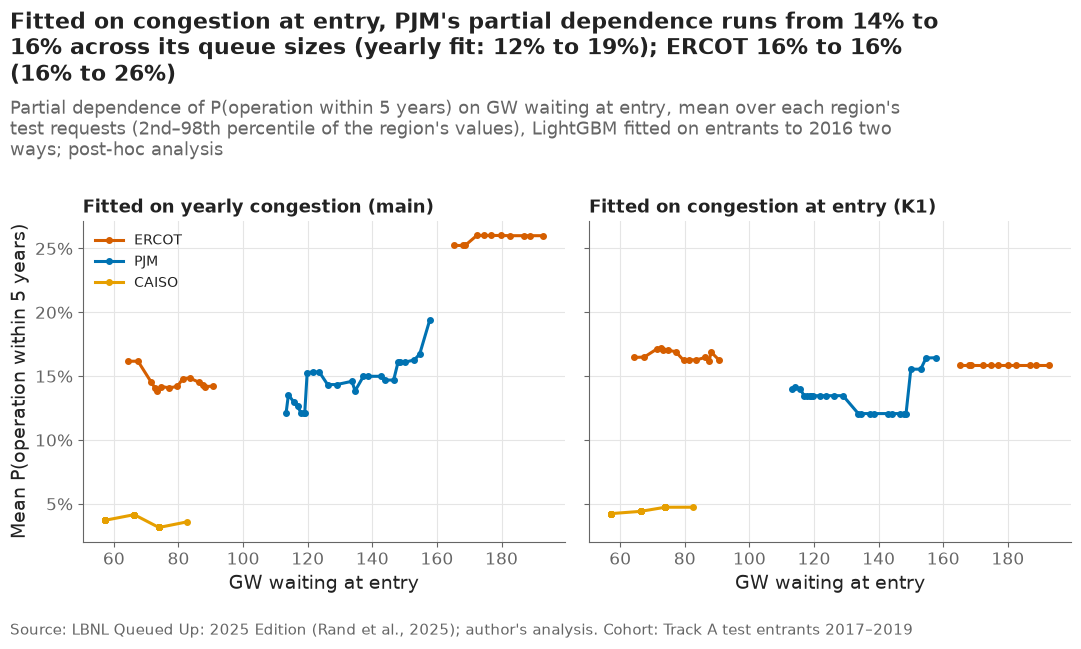

,yearly_low,yearly_high,entry_low,entry_high
region,,,,
CAISO,0.037,0.036,0.042,0.047
ERCOT,0.162,0.260,0.165,0.159
PJM,0.121,0.194,0.140,0.164


In [13]:
STATES = sorted(track_a["state"].astype(str).unique())
fit_main = discrete_time.fit_both(final, clean, tuning)
fit_entry = discrete_time.fit_both(final, clean, tuning, congestion="entry")
f_main, f_entry = (explain.incidence_function(f, STATES, 5) for f in (fit_main, fit_entry))
X_test = explain.encode(test, STATES).to_numpy()
col = explain.FEATURES.index("congestion_gw")
pd_rows = []
for region in config.TRACK_A_REGIONS:
    base = X_test[regions == region]
    for value_gw in np.quantile(test.loc[test["region"] == region, "congestion_gw"], np.linspace(0.02, 0.98, 25)):
        X2 = base.copy()
        X2[:, col] = value_gw
        pd_rows.append({"region": region, "gw": value_gw, "yearly": f_main(X2).mean(), "entry": f_entry(X2).mean()})
pdc = pd.DataFrame(pd_rows)
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, version, title in [(axes[0], "yearly", "Fitted on yearly congestion (main)"), (axes[1], "entry", "Fitted on congestion at entry (K1)")]:
    for region in config.TRACK_A_REGIONS:
        part = pdc[pdc["region"] == region]
        jump = part["gw"].diff() > 20
        for k, (_, run) in enumerate(part.groupby(jump.cumsum())):
            ax.plot(run["gw"], run[version], color=plots.region_color(region), marker="o", markersize=4,
                    label=region if k == 0 else None)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("GW waiting at entry")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[0].set_ylabel("Mean P(operation within 5 years)")
axes[0].legend(loc="upper left", fontsize=10)
ends = pdc.groupby("region").agg(yearly_low=("yearly", "first"), yearly_high=("yearly", "last"),
                                 entry_low=("entry", "first"), entry_high=("entry", "last"))
plots.finish(fig,
             f"Fitted on congestion at entry, PJM's partial dependence runs from {ends.loc['PJM', 'entry_low']:.0%} to "
             f"{ends.loc['PJM', 'entry_high']:.0%} across its queue sizes (yearly fit: {ends.loc['PJM', 'yearly_low']:.0%} to "
             f"{ends.loc['PJM', 'yearly_high']:.0%}); ERCOT {ends.loc['ERCOT', 'entry_low']:.0%} to {ends.loc['ERCOT', 'entry_high']:.0%} "
             f"({ends.loc['ERCOT', 'yearly_low']:.0%} to {ends.loc['ERCOT', 'yearly_high']:.0%})",
             "Partial dependence of P(operation within 5 years) on GW waiting at entry, mean over each region's test requests "
             "(2nd–98th percentile of the region's values), LightGBM fitted on entrants to 2016 two ways; post-hoc analysis",
             "Track A test entrants 2017–2019")
save(fig, "08b_06_congestion_entry_fit", "Post-hoc: partial dependence on GW waiting at entry for LightGBM fitted on yearly and on entry-time congestion.")
plt.show()
ends.round(3)

**Reading this.** Fitted on congestion held at entry, LightGBM's congestion effect is no longer the steep rise of the main fit: in ERCOT the 5-year chance stays flat across queue sizes (16.5% to 15.9%, against 16.2% to 26.0% for the yearly fit), and in PJM the rise shrinks (14.0% to 16.4%, against 12.1% to 19.4%). This supports notebook 09's diagnosis that the positive effect came mostly from fitting on yearly congestion. It does not turn the effect negative as the descriptive pattern (F8) would suggest; the remaining PJM slope may still reflect calendar time, since every PJM test request entered above the training range of 118 GW.

## 7. Checks

In [14]:
decisions_text = (paths.DOCS / "decisions.md").read_text(encoding="utf-8")
runtime = time.time() - START
checks = pd.DataFrame([
    ("decision #34 (protocol) is in docs/decisions.md", "Post-hoc improvement analysis, notebook 08b" in decisions_text),
    ("main components reproduce notebooks 05–06 on 2016 (gap < 1e-9)", max(gap05, gap06) < 1e-9),
    ("main components reproduce the predictions notebook 08 scored (gap < 1e-9)", gap_main < 1e-9),
    ("the choice was written before the first test-cohort score", CHOICE_TIME < first_test_score),
    ("registered LightGBM's criteria lines here equal notebook 08's", bool(same)),
    ("every post-hoc metric has a 95% interval", bool(post[["low", "high"]].notna().all().all())),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "posthoc_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 2.1 minutes


,check,result
0,decision #34 (protocol) is in docs/decisions.md,PASS
1,main components reproduce notebooks 05–06 on 2...,PASS
2,main components reproduce the predictions note...,PASS
3,the choice was written before the first test-c...,PASS
4,registered LightGBM's criteria lines here equa...,PASS
5,every post-hoc metric has a 95% interval,PASS


**Reading this.** All six checks pass: the protocol is in decision #34, the main components reproduce notebooks 05–06 on 2016 and the predictions notebook 08 scored, the choice was written before the first test score, the registered model's criteria lines here equal notebook 08's, and every post-hoc metric has an interval. Run time is under three minutes (printed above; it varies between runs).

## Takeaways

- Chosen on 2016 by the registered rule, K4 (a blend of the entry-congestion logit and LightGBM with Cox) passes 5 of 10 Track A criterion lines on the test cohort, against 6 for the registered LightGBM: the post-hoc repairs do not improve the pre-registered result, which stands.
- The five candidates were indistinguishable on 2016 (mean Brier 0.0994–0.0997), and the test-cohort miscalibration could not be seen there: the main LightGBM was calibrated on 2016 (slopes 0.88–0.96) and miscalibrated only on 2017–2019 entrants.
- K4 improves the average level (inside the observed band in 12 of 18 region and entry-year cells, against 7), but PJM and the 2018–2019 entrants stay over-predicted: the slowdown after 2017 is not repaired.
- Fitting on congestion at entry removes ERCOT's spurious congestion effect and halves PJM's, confirming notebook 09's diagnosis.
- For requests of 20 MW and more, neither model ranks better than region × technology beyond 3 years.

**What goes to the report:** one paragraph in the results section, labelled post-hoc, with 08b_02 and 08b_04; 08b_06 in the limitations next to 09_09; the protocol (decision #34) cited so a reader can see the choice was fixed before scoring.